# UCS420 Lab Assignment 9 — Vision-based Cognitive System
**Roll No.:** 1024160094  
**Name:** Pragun

**Topic:** Medicine Label Reading and Facial Expression Detection

### Setup
- Run this notebook in **Google Colab**.
- Upload the required images when asked.

In [1]:
!apt-get -qq install tesseract-ocr > /dev/null
!pip -q install pytesseract deepface

---
## Q1. Cognitive Assistant for Reading Medicine Labels
- Upload a clear photo of a medicine bottle label.
- Read the text using OCR.
- Find the name, strength and expiry details.

Saving Screenshot 2025-06-12 004736.png to Screenshot 2025-06-12 004736.png


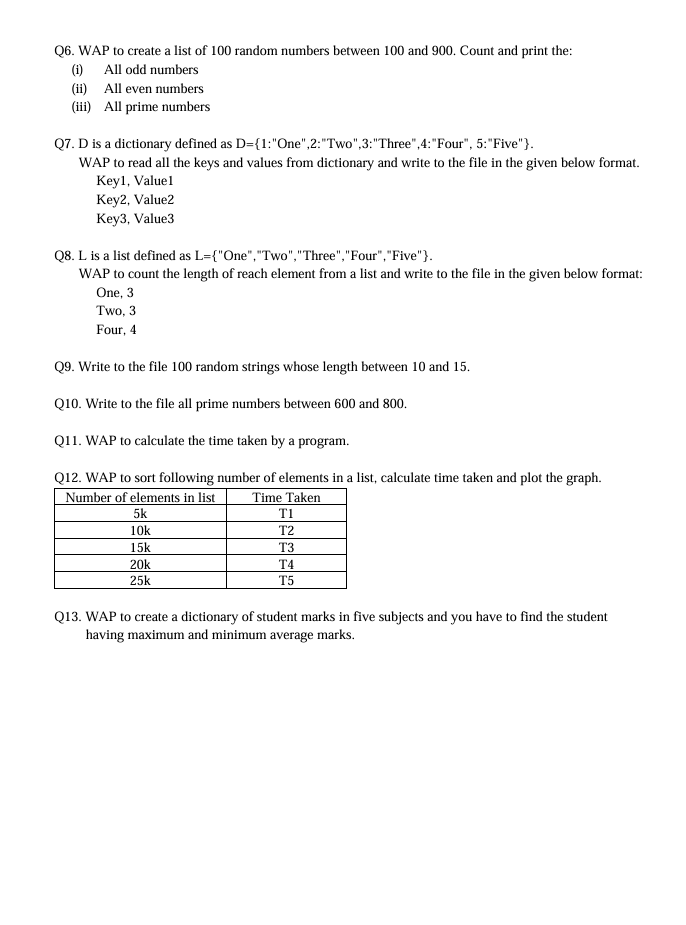

Detected text:
 Q6. WAP to create a list of 100 random numbers between 100 and 900. Count and print the:
()Alllodd numbers
(i) All even numbers
(iii) All prime numbers

QT. Disa dictionary defined as D=(1:"One" 2:"Two",3:" Three" 4:°Four”, 5:"Five").
WAP to read all the keys and values from dictionary and write to the file in the given below format.
Key!, Valuel
Key2, Value2
Key3, Value3

Q8. Lisa list defined as L={"One" ,"Two"," Three","Four", "Five".
WAP to count the length of reach element from a list and write to the file in the given below format:
One, 3
Two, 3
Four, 4

Q9. Write to the file 100 random strings whose length between 10 and 15.
QUO. Write to the file all prime numbers between 600 and 800.
QIL. WAP to calculate the time taken by a program.

Q12. WAP to sort following number of elements in a list, calculate time taken and plot the graph.
ie Taken
TL
T2
T3
TA
15

Q13. WAP to create a dictionary of student marks in five subjects and you have to find the student
having m

In [2]:
from google.colab import files
from PIL import Image
import pytesseract, re

uploaded = files.upload()
label_path = next(iter(uploaded))
img = Image.open(label_path)
display(img)

text = pytesseract.image_to_string(img)
print("Detected text:\n", text)

In [3]:
lines = [line.strip() for line in text.splitlines() if line.strip()]
strength = next((x for x in lines if re.search(r"\b\d+\s*(mg|ml|mcg)\b", x, re.I)), "Not found")
expiry = next((x for x in lines if re.search(r"exp|expiry|use by", x, re.I)), "Not found")

print("Possible medicine name:", lines[0] if lines else "Not found")
print("Strength:", strength)
print("Expiry:", expiry)
print("Assistant: Please verify the label with a pharmacist before use.")

Possible medicine name: Q6. WAP to create a list of 100 random numbers between 100 and 900. Count and print the:
Strength: Not found
Expiry: Not found
Assistant: Please verify the label with a pharmacist before use.


**Observation:**
- OCR reads printed text from the label.
- Clear photos give better results.
- Detected details should be checked before using medicine.

---
## Q2. Emotion-aware Cognitive Assistant
- Upload a clear photo with one face.
- Detect the facial expression.
- Display a simple assistant response.

26-10-27 03:27:41 - Directory /root/.deepface has been created
26-10-27 03:27:41 - Directory /root/.deepface/weights has been created


Saving Screenshot 2025-06-12 011312.png to Screenshot 2025-06-12 011312.png


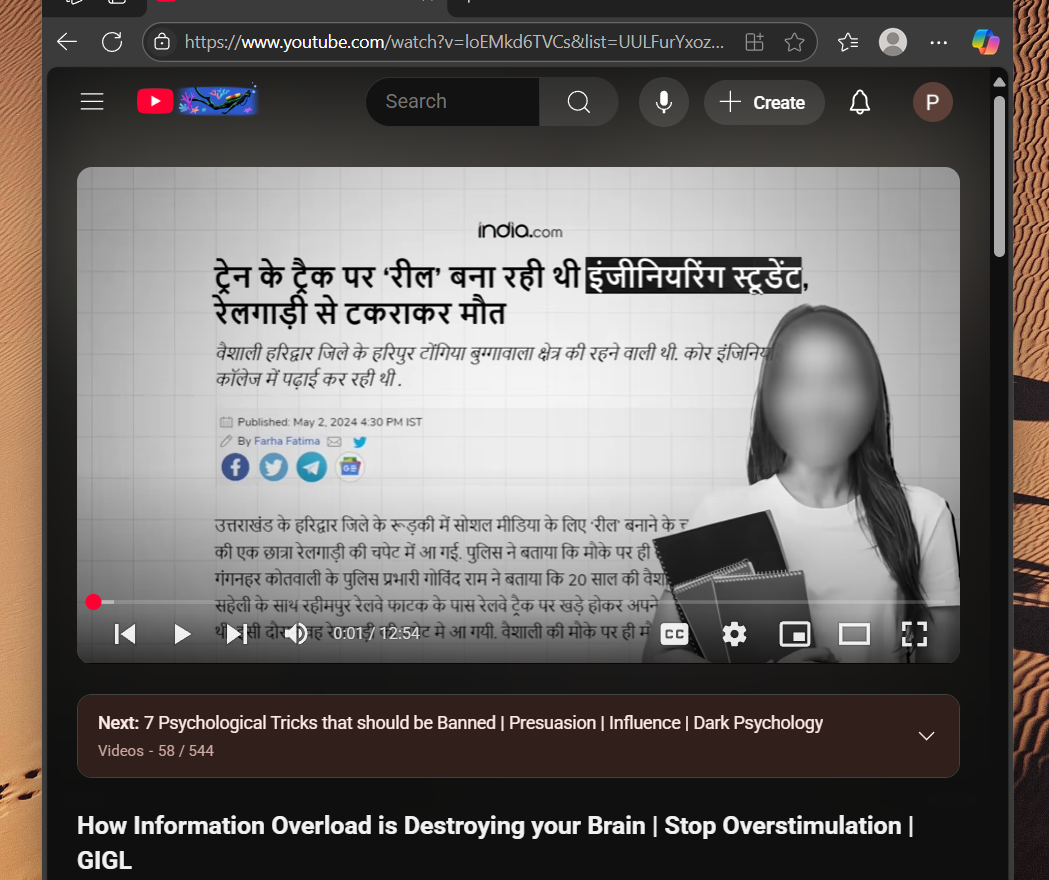

26-10-27 03:27:58 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5
100%|██████████| 5.98M/5.98M [00:00<00:00, 73.5MB/s]


Detected expression: fear
Assistant: How can I help you?


In [4]:
from deepface import DeepFace

uploaded = files.upload()
face_path = next(iter(uploaded))
display(Image.open(face_path))

result = DeepFace.analyze(img_path=face_path, actions=["emotion"])
emotion = result[0]["dominant_emotion"]
print("Detected expression:", emotion)

replies = {"happy": "You look cheerful!", "sad": "Would you like a break?",
           "angry": "Take a short pause.", "neutral": "Hope you are doing well!"}
print("Assistant:", replies.get(emotion, "How can I help you?"))

**Observation:**
- The model predicts an expression such as happy, sad or neutral.
- Facial expressions do not always show a person's real feelings.

---
## Conclusion
- **Q1:** A medicine label is read using OCR.
- **Q2:** A facial expression is used to choose an assistant response.